Calibration of motorized HWP
data0722.csv -- rot of Motor 1, H pol measurement, 1s per angle
data0722_2.csv -- repeated rot of Motor 1, H pol measurement, 1s per angle

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.odr import ODR, Model, RealData

# Columns:
# 0 = Time; 1 = Motor 2 angle; 2 = Motor 1 angle
# 3 = Wavelength; 4 = Power

[hwpV_ang, powerV] = np.loadtxt(
    "data_1s_V.csv",
    delimiter=",",
    skiprows=1,
    #max_rows=4800,
    #usecols=(2, 4),
    unpack=True
)


[hwpH_ang, powerH] = np.loadtxt(
    "data0722_0.3s.csv",
    delimiter=",",
    skiprows=1,
    #max_rows=4800,
    #usecols=(2, 4),
    unpack=True
)

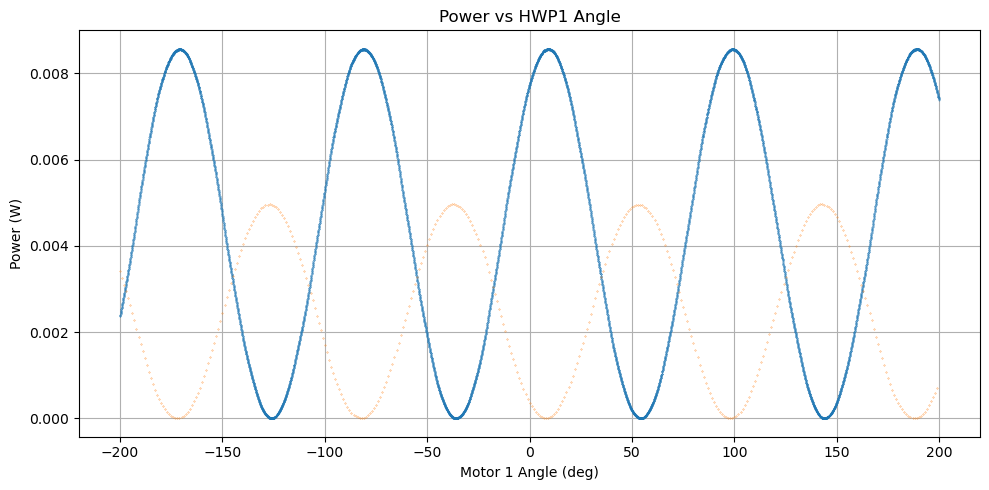

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(hwpH_ang, powerH, marker=".", markersize=0.5, linewidth=0)
plt.plot(hwpV_ang, powerV, marker=".", markersize=0.5, linewidth=0)


plt.xlabel("Motor 1 Angle (deg)")
plt.ylabel("Power (W)")
plt.title("Power vs HWP1 Angle")
plt.grid(True)
plt.tight_layout()
plt.show()

In [11]:
# Joint model:
# Port 1: P1(theta) = Pmin1 + P1*cos^2[2*k*(theta-theta0)]
# Port 2: P2(theta) = Pmin2 + P2*sin^2[2*k*(theta-theta0)]
theta = hwpH_ang

def power_both(beta, theta):
    PminH, PH, PminV, PV, theta0 = beta

    phase = np.deg2rad(2 * (theta - theta0))

    fitH = PminH + PH * np.cos(phase)**2
    fitV = PminV + PV * np.sin(phase)**2

    return np.vstack((fitH, fitV))


power_data = np.vstack((powerH, powerV))

data = RealData(
    theta,
    power_data,
    sx=0.05,
    sy=1e-6
)

odr = ODR(
    data,
    Model(power_both),
    beta0=[
        np.min(powerH),
        np.ptp(powerH),
        np.min(powerV),
        np.ptp(powerV),
        theta[np.argmax(powerH)]
    ]
)

output = odr.run()

PminH, PH, PminV, PV, theta0 = output.beta
PminH_err, PH_err, PminV_err, PV_err, theta0_err = output.sd_beta

theta0 = theta0 % 90
thetaV_max = (theta0 + 45) % 90

# Plot joint fit
theta_fit = np.linspace(
    np.min(hwpH_ang),
    np.max(hwpH_ang),
    2000
)

fit1, fit2 = power_both(output.beta, theta_fit)

plt.figure(figsize=(10, 5))

plt.plot(hwpH_ang, powerH, ".", label="Port 1 data")
plt.plot(theta_fit, fit1, "-", label="Port 1 joint fit")

plt.plot(hwpV_ang, powerV, ".", label="Port 2 data")
plt.plot(theta_fit, fit2, "-", label="Port 2 joint fit")

plt.xlabel("Motor 1 Angle (deg)")
plt.ylabel("Power (W)")
plt.title("Joint complementary PBS-output fit")
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

print("Port 1:")
print(f"Pmin          = {PminH*1000:.8e} ± {PminH_err*1000:.2e} mW")
print(f"P modulation  = {PH*1000:.8e} ± {PH_err*1000:.2e} mW")
print(f"theta_max     = {theta0:.6f} deg")

print("\nPort 2:")
print(f"Pmin          = {PminV*1000:.8e} ± {PminV_err*1000:.2e} mW")
print(f"P modulation  = {PV*1000:.8e} ± {PV_err*1000:.2e} mW")
print(f"theta_max     = {thetaV_max:.6f} deg")

print("\nShared parameters:")
print(f"theta0        = {theta0:.6f} ± {theta0_err:.6f} deg")
print("Stop reason:", output.stopreason)

ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 1, the array at index 0 has size 8000 and the array at index 1 has size 400

RSS H = 0.00014319536492532963
RSS V = 0.000130945563098273


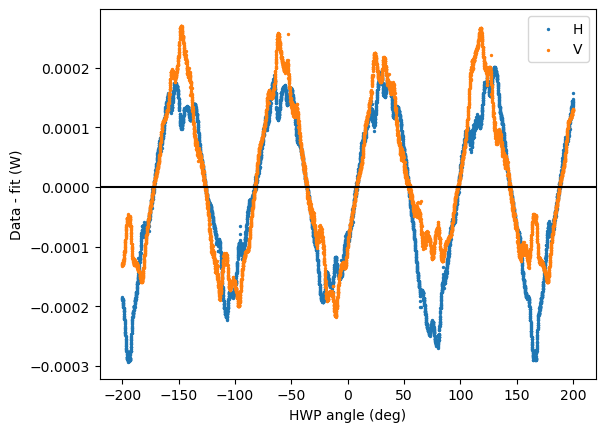

In [ ]:
fitH, fitV = power_both(output.beta, theta)

residualH = powerH - fitH
residualV = powerV - fitV

print("RSS H =", np.sum(residualH**2))
print("RSS V =", np.sum(residualV**2))

plt.figure()
plt.scatter(hwpH_ang, residualH, s=2, label="H")
plt.scatter(hwpV_ang, residualV, s=2, label="V")
plt.axhline(0, color="k")
plt.xlabel("HWP angle (deg)")
plt.ylabel("Data - fit (W)")
plt.legend()
plt.show()